# 05 — Pontualidade

**A pergunta:** quem atrasa mais, onde e em que horário? É a base da
pergunta 3 do README, se pagar mais caro compra pontualidade, que fica pra
segunda parte deste notebook.

Faz parte da [etapa 9](https://github.com/ivadivad/voos-em-numeros#etapas) do projeto. Os dados vêm de
`dados/marts/pontualidade_rota.parquet` e
`dados/marts/pontualidade_horario.parquet`, que o `construir.py` monta a
partir do Voo Regular Ativo (VRA) da coleta de 13/10/2026: os voos
domésticos regulares de passageiros previstos, com os realizados, os
cancelados e os atrasados na chegada, num recorte por grupo, mês e rota, e
noutro por grupo, mês, dia da semana e hora da partida prevista.

## 1. As regras, fixadas antes de rodar

- **Atraso é na chegada, acima de 15 minutos.** Acima de 30 e de 60
  minutos, os dois cortes que a ANAC publica no Anuário (conferidos no
  notebook 01), entram como sensibilidade; se a ordem dos grupos mudar com
  o corte, isso aparece aqui e vai pro README.
- **Sempre percentual, nunca contagem:** quem voa mais atrasa mais voos. O
  atraso é sobre os voos com atraso medido (os realizados com os dois
  horários); o cancelamento, sobre os realizados mais os cancelados.
- **Os voos com situação `NÃO INFORMADO` ficam fora da conta principal**
  (decisão do Davi, 19/10/2026). Como sensibilidade, entram como
  cancelados, o pior caso.
- **Os voos que chegaram 2 h ou mais antes do previsto, ou 23 h ou mais
  depois, ficam na conta principal.** Os dados não separam esses voos de
  uma mudança de horário ou de dia (`DICIONARIO.md`); como sensibilidade,
  saem da conta.
- **Grupo, não marca:** a Azul Conecta conta na Azul, como nos outros
  notebooks. A comparação entre grupos fica com os que têm pelo menos 1%
  dos voos previstos do ano. Os anos vão de 2019 a 2025 inteiros, mais
  2026 de janeiro a agosto; 2020 não tem fevereiro nem março, que não
  existem no VRA.
- **Aeroportos e horários: os 12 meses mais recentes da base**, o retrato
  de hoje, como no notebook 04. Nos aeroportos, os 15 com mais voos
  previstos saindo, com o atraso dos voos que saem e dos que chegam. No
  mapa de calor, a hora é a da partida prevista, no horário de Brasília,
  que é o do VRA, e a célula com menos de 500 voos medidos fica em branco.

In [1]:
import pandas as pd

BASE = "https://raw.githubusercontent.com/ivadivad/voos-em-numeros/coleta-2026-10-13/dados/marts/"
rota = pd.read_parquet(BASE + "pontualidade_rota.parquet")
horario = pd.read_parquet(BASE + "pontualidade_horario.parquet")
aeroporto = pd.read_parquet(BASE + "dim_aeroporto.parquet").set_index("icao")
nome_grupo = pd.read_parquet(BASE + "dim_grupo.parquet").set_index("grupo")["nome_grupo"]
for tabela in (rota, horario):
    tabela["mes"] = pd.to_datetime(tabela["mes"])
    tabela["ano"] = tabela["mes"].dt.year
CONTAGENS = ["voos_previstos", "voos_realizados", "voos_cancelados", "voos_nao_informados", "voos_medidos",
             "voos_atraso_15", "voos_atraso_30", "voos_atraso_60", "voos_adiantados_2h", "voos_atraso_23h"]
print(f"rota: {len(rota)} registros; horário: {len(horario)} registros; de {rota['mes'].min():%m/%Y} a "
      f"{rota['mes'].max():%m/%Y}, {rota['mes'].nunique()} meses com voo")
meses = pd.date_range(rota["mes"].min(), rota["mes"].max(), freq="MS")
print("meses sem voo no VRA:", [f"{m:%m/%Y}" for m in meses.difference(rota["mes"].unique())])
print("os dois recortes somam o mesmo:", rota[CONTAGENS].sum().equals(horario[CONTAGENS].sum()), "\n")
print(rota[CONTAGENS].sum().to_string())
print("realizados sem atraso medido:", rota["voos_realizados"].sum() - rota["voos_medidos"].sum())

rota: 98670 registros; horário: 57972 registros; de 01/2019 a 08/2026, 90 meses com voo
meses sem voo no VRA: ['02/2020', '03/2020']
os dois recortes somam o mesmo: True 

voos_previstos         5173197
voos_realizados        5049318
voos_cancelados         122721
voos_nao_informados       1158
voos_medidos           5049310
voos_atraso_15          723648
voos_atraso_30          355680
voos_atraso_60          133036
voos_adiantados_2h        1817
voos_atraso_23h            263
realizados sem atraso medido: 8


São 98.670 registros por rota e 57.972 por horário, de 01/2019 a 08/2026:
90 meses com voo, porque 02/2020 e 03/2020 não existem no VRA. Os dois
recortes somam o mesmo nas dez contagens. No período, são 5.173.197 voos
previstos: 5.049.318 realizados, 122.721 cancelados e 1.158 com situação
`NÃO INFORMADO`. Dos realizados, 5.049.310 têm o atraso medido; os 8 que
faltam têm a data trocada (`DICIONARIO.md`). Chegaram mais de 15 minutos
depois do previsto 723.648 voos, e mais de 60, 133.036.

## 2. Quem atrasa mais

In [2]:
def taxas(dados, por, corte=15, nao_informado_cancela=False, sem_pontas=False):
    """Percentual de atraso e de cancelamento, das somas das contagens.

    Atraso: atrasados acima do corte sobre os voos com atraso medido.
    Cancelamento: cancelados sobre realizados mais cancelados. As duas
    sensibilidades declaradas: NAO INFORMADO contado como cancelado, e sem
    as pontas (2 h antes, que saem do denominador; 23 h depois, que saem dos
    dois).
    """
    s = dados.groupby(por)[CONTAGENS].sum()
    medidos, atrasados = s["voos_medidos"], s[f"voos_atraso_{corte}"]
    if sem_pontas:
        medidos = medidos - s["voos_adiantados_2h"] - s["voos_atraso_23h"]
        atrasados = atrasados - s["voos_atraso_23h"]
    cancelados = s["voos_cancelados"] + (s["voos_nao_informados"] if nao_informado_cancela else 0)
    return pd.DataFrame({
        "voos": s["voos_previstos"],
        "atraso (%)": atrasados / medidos * 100,
        "cancelados (%)": cancelados / (s["voos_realizados"] + cancelados) * 100,
    })


anual = taxas(rota, ["ano", "grupo"])
anual["% dos voos do ano"] = anual["voos"] / anual.groupby(level="ano")["voos"].transform("sum") * 100
NO_RANKING = anual.index[anual["% dos voos do ano"] >= 1]
ranking = anual.loc[NO_RANKING]
for coluna in ["% dos voos do ano", "atraso (%)", "cancelados (%)"]:
    print(coluna, "por ano, nos grupos com pelo menos 1% dos voos previstos do ano")
    print(ranking[coluna].unstack("ano").round(1).to_string(), "\n")

% dos voos do ano por ano, nos grupos com pelo menos 1% dos voos previstos do ano
ano       2019  2020  2021  2022  2023  2024  2025  2026
grupo                                                   
AZUL      35.8  39.4  44.3  41.3  39.5  40.8  37.9  35.2
GOL       30.4  31.0  25.2  27.0  27.1  25.4  27.9  29.7
LATAM     27.5  25.8  26.9  29.2  30.8  31.2  33.7  35.0
OCEANAIR   3.3   NaN   NaN   NaN   NaN   NaN   NaN   NaN
VOEPASS    1.8   2.8   2.6   2.4   2.5   2.4   NaN   NaN 

atraso (%) por ano, nos grupos com pelo menos 1% dos voos previstos do ano
ano       2019  2020  2021  2022  2023  2024  2025  2026
grupo                                                   
AZUL      15.3  11.2   9.5  11.2  13.9  16.9  14.2  14.1
GOL       18.8  12.2  12.1  18.3  22.1  15.1  11.5  12.7
LATAM      7.9   5.3   6.8  10.9  16.7  14.1  16.2  18.5
OCEANAIR  23.9   NaN   NaN   NaN   NaN   NaN   NaN   NaN
VOEPASS   29.6  15.2  16.4  21.6  27.7  31.0   NaN   NaN 

cancelados (%) por ano, nos grupos com pe

**A VoePass é a que mais atrasa e a que mais cancela em todos os anos em
que tem pelo menos 1% dos voos**, de 2019 a 2024: de 15,2% a 31,0% de
atraso, e de 10,3% a 15,4% de cancelamento a partir de 2020. A Oceanair, o
grupo da Avianca Brasil, só aparece em 2019.

**Entre as três maiores, a ordem virou.** A LATAM foi de 7,9% de atraso em
2019 a 18,5% em 2026; a GOL, que chegou a 22,1% em 2023, está em 12,7%; a
Azul ficou entre 9,5% e 16,9% o período todo. No cancelamento, a Azul fica
acima da GOL e da LATAM em todos os anos menos 2021, com o pico de 2022 a
2024: 4,7%, 4,3% e 4,4%. O ano de 2026 vai só até agosto.

In [3]:
def ordem(tabela):
    """Os grupos de cada ano, do que menos atrasa ao que mais atrasa."""
    return tabela["atraso (%)"].groupby(level="ano").apply(
        lambda ano: " < ".join(ano.sort_values().index.get_level_values("grupo")))


ordens = pd.DataFrame({f"acima de {corte} min": ordem(taxas(rota, ["ano", "grupo"], corte=corte).loc[NO_RANKING])
                       for corte in (15, 30, 60)})
print(ordens.to_string(), "\n")
mudam = [ano for ano, linha in ordens.iterrows() if linha.nunique() > 1]
print("anos em que a ordem muda com o corte:", mudam)

                              acima de 15 min                          acima de 30 min                          acima de 60 min
ano                                                                                                                            
2019  LATAM < AZUL < GOL < OCEANAIR < VOEPASS  LATAM < AZUL < GOL < OCEANAIR < VOEPASS  LATAM < AZUL < GOL < OCEANAIR < VOEPASS
2020             LATAM < AZUL < GOL < VOEPASS             LATAM < AZUL < GOL < VOEPASS             LATAM < GOL < AZUL < VOEPASS
2021             LATAM < AZUL < GOL < VOEPASS             LATAM < AZUL < GOL < VOEPASS             LATAM < AZUL < GOL < VOEPASS
2022             LATAM < AZUL < GOL < VOEPASS             LATAM < AZUL < GOL < VOEPASS             LATAM < AZUL < GOL < VOEPASS
2023             AZUL < LATAM < GOL < VOEPASS             AZUL < LATAM < GOL < VOEPASS             LATAM < AZUL < GOL < VOEPASS
2024             LATAM < GOL < AZUL < VOEPASS             LATAM < GOL < AZUL < VOEPASS             LATAM

**A ordem muda com o corte em quatro dos oito anos: 2020, 2023, 2025 e
2026.** Em 2025, a LATAM é a que mais atrasa acima de 15 minutos, e a
Azul, acima de 30 e de 60; em 2026, a troca entre as duas acontece só no
corte de 60. Em 2020, a GOL e a Azul trocam de lugar no corte de 60. E o
grupo que menos atrasa só muda com o corte em 2023: a Azul acima de 15 e
de 30 minutos, a LATAM acima de 60.

O corte de 15 minutos continua sendo a régua principal, mas a ordem entre
a LATAM e a Azul nos anos recentes depende dele. Como as regras pedem,
isso vai pro README.

In [4]:
print("voos com situação NÃO INFORMADO, por grupo:")
print(rota.groupby("grupo")["voos_nao_informados"].sum().loc[lambda s: s > 0].to_string(), "\n")

comparacao = pd.DataFrame({
    "cancelados (%)": ranking["cancelados (%)"],
    "com NÃO INFORMADO como cancelado": taxas(rota, ["ano", "grupo"], nao_informado_cancela=True)
    .loc[NO_RANKING, "cancelados (%)"],
    "atraso (%)": ranking["atraso (%)"],
    "sem as pontas": taxas(rota, ["ano", "grupo"], sem_pontas=True).loc[NO_RANKING, "atraso (%)"],
})
comparacao["diferença no cancelamento"] = comparacao.iloc[:, 1] - comparacao.iloc[:, 0]
comparacao["diferença no atraso"] = comparacao.iloc[:, 3] - comparacao.iloc[:, 2]
print(comparacao.round(2).to_string(), "\n")
print("maior diferença no cancelamento:", round(comparacao["diferença no cancelamento"].max(), 2), "ponto;",
      "maior diferença no atraso:", round(comparacao["diferença no atraso"].abs().max(), 2), "ponto")
print("a ordem muda sem as pontas:",
      not ordem(taxas(rota, ["ano", "grupo"], sem_pontas=True).loc[NO_RANKING]).equals(ordens["acima de 15 min"]))

voos com situação NÃO INFORMADO, por grupo:
grupo
AEROSUL      4
APUI       810
VOEPASS    344 

               cancelados (%)  com NÃO INFORMADO como cancelado  atraso (%)  sem as pontas  diferença no cancelamento  diferença no atraso
ano  grupo                                                                                                                                
2019 AZUL                1.93                              1.93       15.31          15.31                       0.00                 0.00
     GOL                 1.24                              1.24       18.83          18.82                       0.00                -0.00
     LATAM               0.86                              0.86        7.95           7.95                       0.00                -0.00
     OCEANAIR            2.30                              2.30       23.87          23.76                       0.00                -0.11
     VOEPASS             5.60                              5.60      

**Nenhuma das duas sensibilidades muda o retrato.** Os 1.158 voos `NÃO
INFORMADO` são da Apuí (810), da VoePass (344) e da Aerosul (4). Contados
como cancelados, só mexem na VoePass, que já é a que mais cancela: mais
1,63 ponto em 2020 e 1,02 em 2022. A Apuí não chega a 1% dos voos em
nenhum ano. Sem as pontas, o atraso muda no máximo 0,38 ponto (a VoePass,
em 2022), e a ordem dos grupos fica a mesma em todos os anos.

## 3. Mês a mês

os três grupos com mais voos previstos: ['AZUL', 'LATAM', 'GOL']
o que mais atrasa, por ano: {2019: 'GOL', 2020: 'GOL', 2021: 'GOL', 2022: 'GOL', 2023: 'GOL', 2024: 'AZUL', 2025: 'LATAM', 2026: 'LATAM'}
o que menos atrasa, por ano: {2019: 'LATAM', 2020: 'LATAM', 2021: 'LATAM', 2022: 'LATAM', 2023: 'AZUL', 2024: 'LATAM', 2025: 'GOL', 2026: 'GOL'}
LATAM: o que mais atrasa desde 2025; o que menos atrasou em 5 de 6 anos antes disso
AZUL: pior mês de atraso 12/2024 (25.5%), de cancelamento 06/2020 (7.6%)
LATAM: pior mês de atraso 12/2025 (28.9%), de cancelamento 04/2020 (10.1%)
GOL: pior mês de atraso 12/2022 (35.2%), de cancelamento 03/2021 (9.0%)
gravado: 05-atraso-por-mes.png


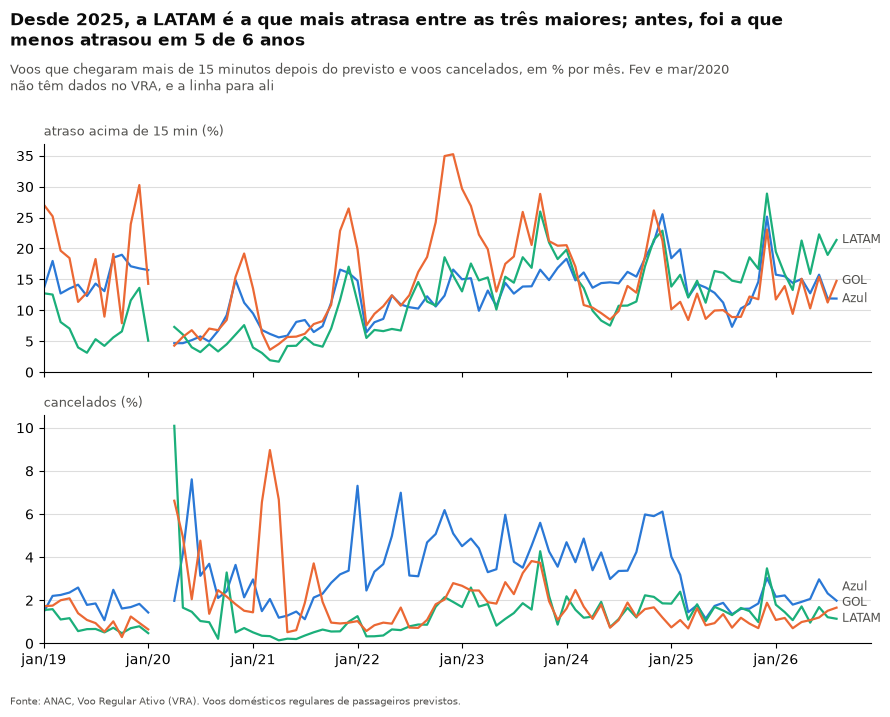

In [5]:
import os
import sys
import urllib.request

if os.path.exists("../visual.py"):
    sys.path.insert(0, "..")
else:  # fora do repositorio (no Colab): o padrao visual vem pela URL bruta
    urllib.request.urlretrieve("https://raw.githubusercontent.com/ivadivad/voos-em-numeros/coleta-2026-10-13/visual.py", "visual.py")
from visual import AZUL, LARANJA, TEXTO_SECUNDARIO, VERDE, grafico, salvar

TRES = anual.groupby("grupo")["voos"].sum().nlargest(3).index.tolist()
CORES = dict(zip(["AZUL", "GOL", "LATAM"], [AZUL, LARANJA, VERDE]))
print("os três grupos com mais voos previstos:", TRES)

# o que o titulo afirma, contado dos dados
tres_anual = anual.loc[anual.index.get_level_values("grupo").isin(TRES), "atraso (%)"].unstack("grupo")
pior, melhor = tres_anual.idxmax(axis=1), tres_anual.idxmin(axis=1)
ultimo = pior.iloc[-1]
desde = pior.index[-1]
while desde - 1 in pior.index and pior[desde - 1] == ultimo:
    desde -= 1
antes = melhor[melhor.index < desde]
print("o que mais atrasa, por ano:", pior.to_dict())
print("o que menos atrasa, por ano:", melhor.to_dict())
print(f"{ultimo}: o que mais atrasa desde {desde}; o que menos atrasou em {(antes == ultimo).sum()} "
      f"de {len(antes)} anos antes disso")

mensal = taxas(rota[rota["grupo"].isin(TRES)], ["mes", "grupo"])
for grupo in TRES:
    serie = mensal.xs(grupo, level="grupo")
    print(f"{grupo}: pior mês de atraso {serie['atraso (%)'].idxmax():%m/%Y} ({serie['atraso (%)'].max():.1f}%), "
          f"de cancelamento {serie['cancelados (%)'].idxmax():%m/%Y} ({serie['cancelados (%)'].max():.1f}%)")


def rotular(ax, pontos):
    """Nome no fim de cada linha, afastando os que ficariam um sobre o outro."""
    baixo, alto = ax.get_ylim()
    anterior = None
    for x, y, texto in sorted(pontos, key=lambda ponto: ponto[1]):
        if anterior is not None:
            y = max(y, anterior + (alto - baixo) * 0.07)
        anterior = y
        ax.annotate(texto, (x, y), xytext=(4, 0), textcoords="offset points", va="center",
                    fontsize=8.5, color=TEXTO_SECUNDARIO)


fig, (ax1, ax2) = grafico(
    f"Desde {desde}, a {nome_grupo[ultimo]} é a que mais atrasa entre as três maiores; antes, foi a que\n"
    f"menos atrasou em {(antes == ultimo).sum()} de {len(antes)} anos",
    subtitulo="Voos que chegaram mais de 15 minutos depois do previsto e voos cancelados, em % por mês. "
              "Fev e mar/2020\nnão têm dados no VRA, e a linha para ali",
    fonte="Fonte: ANAC, Voo Regular Ativo (VRA). Voos domésticos regulares de passageiros previstos.",
    linhas=2, figsize=(9, 7.2))
pontas = {ax1: [], ax2: []}
for grupo in TRES:
    serie = mensal.xs(grupo, level="grupo").reindex(meses)
    for ax, coluna in [(ax1, "atraso (%)"), (ax2, "cancelados (%)")]:
        ax.plot(serie.index, serie[coluna], color=CORES[grupo], linewidth=1.6)
        pontas[ax].append((serie.index[-1], serie[coluna].iloc[-1], nome_grupo[grupo]))
ax1.set_title("atraso acima de 15 min (%)", loc="left", fontsize=9, color=TEXTO_SECUNDARIO)
ax2.set_title("cancelados (%)", loc="left", fontsize=9, color=TEXTO_SECUNDARIO)
for ax in (ax1, ax2):
    ax.set_ylim(bottom=0)
    ax.set_xlim(meses[0], meses[-1] + pd.DateOffset(months=4))
    rotular(ax, pontas[ax])
caminho = salvar(fig, "05-atraso-por-mes.png")
print("gravado:", os.path.basename(caminho))

**Mês a mês, a LATAM passa a liderar o atraso a partir de 2025**, e o pior
mês de cada uma das três é um dezembro: a GOL chegou a 35,2% de atraso em
12/2022, a Azul a 25,5% em 12/2024 e a LATAM a 28,9% em 12/2025. Os picos
de cancelamento são de 2020 e 2021: 10,1% da LATAM em 04/2020, 7,6% da
Azul em 06/2020 e 9,0% da GOL em 03/2021. O gráfico mostra quando, mas a
causa de cada pico não está nos dados.

## 4. Onde: os aeroportos

O atraso é sempre medido na chegada. "Saindo" é o atraso, no destino, dos
voos que partem do aeroporto; "chegando", o dos voos que pousam nele.

In [6]:
fim = rota["mes"].max()
inicio = fim - pd.DateOffset(months=11)
janela = rota[rota["mes"] >= inicio]
print(f"janela: {inicio:%m/%Y} a {fim:%m/%Y}")
maiores = janela.groupby("origem")["voos_previstos"].sum().nlargest(15).index
saindo = taxas(janela, "origem").loc[maiores]
chegando = taxas(janela, "destino").loc[maiores]
tabela = pd.DataFrame({
    "cidade": aeroporto.loc[maiores, "nome_cidade"],
    "voos saindo": saindo["voos"],
    "atraso saindo (%)": saindo["atraso (%)"].round(1),
    "atraso chegando (%)": chegando["atraso (%)"].round(1),
    "cancelados saindo (%)": saindo["cancelados (%)"].round(1),
})
print(tabela.to_string(), "\n")
geral = janela[CONTAGENS].sum()
print(f"todos os voos da janela: atraso {geral['voos_atraso_15'] / geral['voos_medidos'] * 100:.1f}%, "
      f"cancelados {geral['voos_cancelados'] / (geral['voos_realizados'] + geral['voos_cancelados']) * 100:.1f}%")
print("o pior pra sair:", tabela["atraso saindo (%)"].idxmax(), "| o pior pra chegar:",
      tabela["atraso chegando (%)"].idxmax())
print("o mais pontual pra sair:", tabela["atraso saindo (%)"].idxmin(), "| pra chegar:",
      tabela["atraso chegando (%)"].idxmin(), "| o que mais cancela:", tabela["cancelados saindo (%)"].idxmax())
mais_chegando = tabela.index[tabela["atraso chegando (%)"] > tabela["atraso saindo (%)"]].tolist()
print(f"chegar atrasa mais que sair em {len(mais_chegando)} dos {len(tabela)}; sair atrasa mais em:",
      tabela.index.difference(mais_chegando).tolist())

janela: 09/2025 a 08/2026
                     cidade  voos saindo  atraso saindo (%)  atraso chegando (%)  cancelados saindo (%)
origem                                                                                                 
SBGR              São Paulo        96027               26.4                 19.9                    1.1
SBSP              São Paulo        95043               17.6                 14.0                    1.9
SBBR               Brasília        56151               11.1                 12.5                    0.9
SBCF         Belo Horizonte        53633               15.0                 15.5                    1.5
SBKP              São Paulo        51171               16.5                 14.8                    1.8
SBGL         Rio de Janeiro        42643               12.0                 11.9                    0.8
SBRF                 Recife        34028               13.5                 14.3                    1.2
SBRJ         Rio de Janeiro        294

**Guarulhos é o pior aeroporto pra sair e pra chegar**: 26,4% dos voos
que saem de lá chegam atrasados ao destino, e 19,9% dos que pousam lá,
contra 15,7% de todos os voos da janela. Brasília é o mais pontual pra
sair (11,1%), e o Galeão, pra chegar (11,9%). O Santos Dumont é o que mais
cancela (3,3%).

**Em 11 dos 15, chegar atrasa mais que sair.** As exceções são Guarulhos,
Congonhas e Viracopos, os três de São Paulo, e o Galeão, quase empatado
(12,0% e 11,9%). É compatível com atraso que nasce em São Paulo e se
espalha pela malha, mas a tabela não prova isso: o mart não segue o avião
de um voo pro seguinte.

## 5. Quando: a hora e o dia da semana

atraso acima de 15 min (%), 09/2025 a 08/2026; vazio: menos de 500 voos medidos
hora    0    1     2     3    4    5    6     7     8     9     10    11    12    13    14    15    16    17    18    19    20    21    22    23
seg   16.0  6.0   9.0   7.0  6.0  6.0  6.0  11.0  12.0  12.0  13.0  14.0  15.0  15.0  15.0  18.0  18.0  19.0  21.0  21.0  19.0  15.0  22.0  24.0
ter   18.0  NaN  11.0   9.0  6.0  7.0  8.0  12.0  12.0  12.0  12.0  14.0  15.0  15.0  16.0  19.0  19.0  20.0  22.0  22.0  20.0  15.0  22.0  23.0
qua   13.0  NaN  11.0   9.0  7.0  7.0  8.0  13.0  13.0  14.0  13.0  15.0  17.0  17.0  17.0  20.0  19.0  21.0  22.0  22.0  21.0  16.0  23.0  26.0
qui   20.0  NaN  12.0  10.0  7.0  8.0  8.0  13.0  13.0  14.0  14.0  16.0  18.0  18.0  18.0  21.0  22.0  24.0  25.0  26.0  23.0  18.0  24.0  26.0
sex   12.0  NaN  11.0   9.0  7.0  6.0  7.0  12.0  14.0  14.0  15.0  16.0  19.0  20.0  21.0  23.0  23.0  25.0  26.0  25.0  25.0  18.0  22.0  24.0
sáb   13.0  NaN  13.0  11.0  8.0  8.0  8.0  13.0  

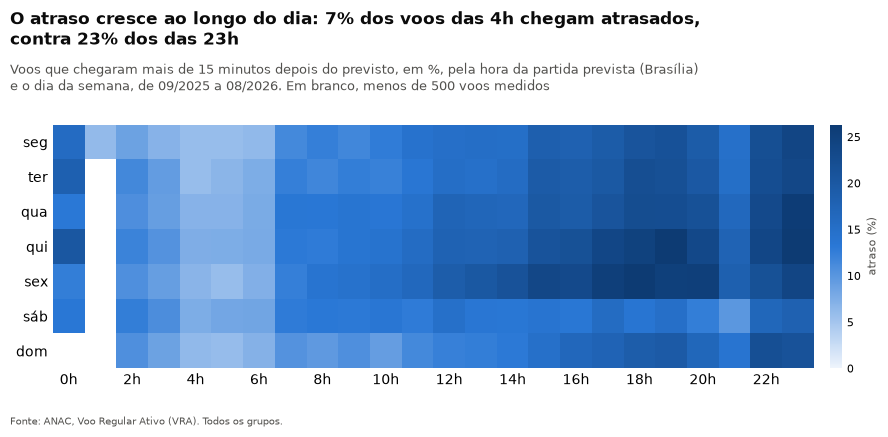

In [7]:
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

DIAS = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
MINIMO = 500
h = horario[horario["mes"] >= inicio].groupby(["dia_semana", "hora"])[CONTAGENS].sum()
celulas = (h["voos_atraso_15"] / h["voos_medidos"] * 100).where(h["voos_medidos"] >= MINIMO).unstack("hora")
celulas = celulas.reindex(index=range(1, 8), columns=range(24))
celulas.index = DIAS
print(f"atraso acima de 15 min (%), {inicio:%m/%Y} a {fim:%m/%Y}; vazio: menos de {MINIMO} voos medidos")
print(celulas.round(0).to_string(), "\n")

por_hora = horario[horario["mes"] >= inicio].groupby("hora")[CONTAGENS].sum()
print("voos previstos por hora da partida:", por_hora["voos_previstos"].to_dict())
print("hora com menos voos:", por_hora["voos_previstos"].idxmin(), "| com mais:", por_hora["voos_previstos"].idxmax())
perfil = (por_hora["voos_atraso_15"] / por_hora["voos_medidos"] * 100).where(por_hora["voos_medidos"] >= MINIMO)
cedo, tarde = perfil.idxmin(), perfil.idxmax()
print(f"atraso por hora, todos os dias: o menor às {cedo}h ({perfil[cedo]:.1f}%), o maior às {tarde}h "
      f"({perfil[tarde]:.1f}%)")
print("célula mais pontual:", celulas.stack().idxmin(), round(celulas.stack().min(), 1),
      "| mais atrasada:", celulas.stack().idxmax(), round(celulas.stack().max(), 1))

azuis = LinearSegmentedColormap.from_list("azuis", ["#eef4fc", AZUL, "#0d3b73"])
azuis.set_bad("white")
fig, ax = grafico(f"O atraso cresce ao longo do dia: {perfil[cedo]:.0f}% dos voos das {cedo}h chegam atrasados,"
                  f"\ncontra {perfil[tarde]:.0f}% dos das {tarde}h",
                  subtitulo=f"Voos que chegaram mais de 15 minutos depois do previsto, em %, pela hora da partida "
                            f"prevista (Brasília)\ne o dia da semana, de {inicio:%m/%Y} a {fim:%m/%Y}. "
                            f"Em branco, menos de {MINIMO} voos medidos",
                  fonte="Fonte: ANAC, Voo Regular Ativo (VRA). Todos os grupos.", figsize=(9, 4.4))
ax.grid(False)
imagem = ax.imshow(np.ma.masked_invalid(celulas.to_numpy()), cmap=azuis, aspect="auto", vmin=0)
ax.set_yticks(range(7), DIAS)
ax.set_xticks(range(0, 24, 2), [f"{hora}h" for hora in range(0, 24, 2)])
ax.tick_params(length=0)
for lado in ("left", "bottom"):
    ax.spines[lado].set_visible(False)
barra = fig.colorbar(imagem, ax=ax, fraction=0.03, pad=0.02)
barra.ax.tick_params(labelsize=8, length=0)
barra.outline.set_visible(False)
barra.set_label("atraso (%)", fontsize=8, color=TEXTO_SECUNDARIO)
caminho = salvar(fig, "05-mapa-de-calor.png")
print("gravado:", os.path.basename(caminho))

**Quanto mais tarde a partida, maior o atraso.** Juntando todos os dias,
6,7% dos voos das 4h chegam atrasados, contra 23,3% dos das 23h. A célula
mais pontual é a segunda-feira às 5h (5,8%); a mais atrasada, a quinta às
19h (26,3%). Quinta e sexta têm os piores fins de tarde, e o sábado é o
dia mais leve a partir das 15h. Uma exceção se repete todo dia: às 21h, o
atraso fica abaixo do das 20h e do das 22h, de 10% no sábado a 18% na
quinta e na sexta.

A hora com menos voos é 1h, e a com mais, 17h. No horário de Brasília,
que é o do VRA (conferido na etapa 1, `DICIONARIO.md`), isso faz sentido;
se a hora fosse UTC, o vale cairia às 22h e o pico às 14h de Brasília.

## 6. Pagar mais caro compra pontualidade?

As regras, fixadas antes de rodar:

- **A unidade é o grupo num mercado**, nos 12 meses mais recentes, a mesma
  janela das seções 4 e 5. A tarifa por km vem do mart de mercado
  (`mercado_mes.parquet`): a receita sobre os assentos-km, só nos mercados
  com distância, como nos notebooks 02 e 03. O atraso acima de 15 minutos
  vem do mart por rota, somado no mercado.
- **Entram os pares com pelo menos 100 voos medidos e 1.000 assentos
  vendidos** na janela: abaixo disso, um mês ruim decide o percentual.
- **Correlação de Spearman**, que olha a ordem e não o valor. Se pagar mais
  comprasse pontualidade, os pares mais caros por km atrasariam menos, e a
  correlação seria negativa. O intervalo de 95% vem de 1.000 reamostragens
  dos pares, com semente fixa.
- **Três recortes**: todos os pares; dentro de cada faixa de distância do
  notebook 03 (até 500 km, 500 a 1.000, 1.000 a 2.000 e acima de 2.000),
  porque a tarifa por km cai com a distância; e dentro de cada um dos três
  maiores grupos, pra ver se o mesmo grupo cobra mais onde atrasa menos.
  Em cada faixa, o atraso dos pares do quartil mais barato de tarifa por km
  contra o do mais caro. E, como sensibilidade, cada ano inteiro de 2019 a
  2025.

In [8]:
mercado_mes = pd.read_parquet(BASE + "mercado_mes.parquet")
mercado_mes["mes"] = pd.to_datetime(mercado_mes["mes"])
mercado_mes["ano"] = mercado_mes["mes"].dt.year
distancia = pd.read_parquet(BASE + "dim_mercado.parquet").set_index("mercado")["distancia_km"].astype(float)
FAIXAS = [0, 500, 1000, 2000, float("inf")]
NOMES_FAIXAS = ["até 500 km", "500 a 1.000 km", "1.000 a 2.000 km", "acima de 2.000 km"]
MIN_VOOS, MIN_ASSENTOS = 100, 1000


def pares(tarifas, voos):
    """Um registro por grupo e mercado: tarifa por km (so o que tem distancia)
    e atraso acima de 15 min, das somas, com os minimos declarados."""
    t = tarifas[tarifas["assentos_km"].notna()].groupby(["grupo", "mercado"])[
        ["receita", "assentos_km", "assentos_vendidos"]].sum()
    v = voos.groupby(["grupo", "mercado"])[["voos_medidos", "voos_atraso_15"]].sum()
    p = t.join(v, how="inner")
    p = p[(p["voos_medidos"] >= MIN_VOOS) & (p["assentos_vendidos"] >= MIN_ASSENTOS)].copy()
    p["tarifa por km"] = p["receita"] / p["assentos_km"]
    p["atraso (%)"] = p["voos_atraso_15"] / p["voos_medidos"] * 100
    p["faixa"] = pd.cut(p.index.get_level_values("mercado").map(distancia), FAIXAS, labels=NOMES_FAIXAS)
    return p


def spearman(p):
    return p["tarifa por km"].corr(p["atraso (%)"], method="spearman")


def intervalo(p, sorteios=1000):
    """Intervalo de 95% da correlacao, reamostrando os pares (semente fixa)."""
    gerador = np.random.default_rng(0)
    valores = [spearman(p.iloc[gerador.integers(0, len(p), len(p))]) for _ in range(sorteios)]
    return np.percentile(valores, [2.5, 97.5])


janela_pares = pares(mercado_mes[mercado_mes["mes"] >= inicio], janela)
print(f"{inicio:%m/%Y} a {fim:%m/%Y}: {len(janela_pares)} pares de grupo e mercado, "
      f"{janela_pares.index.get_level_values('mercado').nunique()} mercados")
linhas = []
recortes = [("todos os pares", janela_pares)]
recortes += [(faixa, janela_pares[janela_pares["faixa"] == faixa]) for faixa in NOMES_FAIXAS]
recortes += [(f"só {nome_grupo[g]}", janela_pares.xs(g, level="grupo", drop_level=False)) for g in TRES]
for nome, p in recortes:
    baixo, alto = intervalo(p)
    linhas.append({"recorte": nome, "pares": len(p), "Spearman": round(spearman(p), 3),
                   "intervalo de 95%": f"{baixo:.3f} a {alto:.3f}"})
print(pd.DataFrame(linhas).to_string(index=False))

09/2025 a 08/2026: 413 pares de grupo e mercado, 259 mercados
          recorte  pares  Spearman intervalo de 95%
   todos os pares    413    -0.090  -0.182 a -0.004
       até 500 km     87     0.121   -0.089 a 0.331
   500 a 1.000 km    122    -0.103   -0.284 a 0.066
 1.000 a 2.000 km    146    -0.221  -0.368 a -0.066
acima de 2.000 km     58    -0.115   -0.347 a 0.154
          só Azul    172    -0.045   -0.188 a 0.099
         só LATAM    116    -0.082   -0.251 a 0.098
           só GOL    124    -0.155   -0.310 a 0.032


**Na janela, a correlação tem o sinal da hipótese, mas é fraca**: −0,090
nos 413 pares, com intervalo de −0,182 a −0,004, que quase toca o zero.
Por faixa de distância, só a de 1.000 a 2.000 km fica com o intervalo
inteiro abaixo de zero (−0,221); até 500 km, o sinal é o contrário
(0,121), e nas outras duas o intervalo cruza o zero. Dentro de cada grupo,
nenhum intervalo exclui o zero: nem a Azul, nem a LATAM, nem a GOL cobram,
de forma clara, mais onde atrasam menos.

In [9]:
linhas = []
for faixa in NOMES_FAIXAS:
    p = janela_pares[janela_pares["faixa"] == faixa].copy()
    p["quartil"] = pd.qcut(p["tarifa por km"], 4, labels=["mais barato", "2º", "3º", "mais caro"])
    s = p.groupby("quartil", observed=True)[["voos_medidos", "voos_atraso_15", "receita", "assentos_km"]].sum()
    for quartil in ["mais barato", "mais caro"]:
        linhas.append({"faixa": faixa, "quartil de tarifa por km": quartil, "pares": int((p["quartil"] == quartil).sum()),
                       "tarifa por km (R$)": round(s.loc[quartil, "receita"] / s.loc[quartil, "assentos_km"], 2),
                       "atraso (%)": round(s.loc[quartil, "voos_atraso_15"] / s.loc[quartil, "voos_medidos"] * 100, 1)})
print("atraso acima de 15 min nos pares do quartil mais barato e do mais caro, em cada faixa")
print(pd.DataFrame(linhas).to_string(index=False))

atraso acima de 15 min nos pares do quartil mais barato e do mais caro, em cada faixa
            faixa quartil de tarifa por km  pares  tarifa por km (R$)  atraso (%)
       até 500 km              mais barato     22                0.91        11.9
       até 500 km                mais caro     22                2.26        13.2
   500 a 1.000 km              mais barato     31                0.57        15.8
   500 a 1.000 km                mais caro     31                1.12        14.5
 1.000 a 2.000 km              mais barato     37                0.38        13.4
 1.000 a 2.000 km                mais caro     37                0.65        12.0
acima de 2.000 km              mais barato     15                0.31        17.9
acima de 2.000 km                mais caro     15                0.48        14.6


**O quartil mais caro atrasa menos em três das quatro faixas, mas por
pouco**: 14,5% contra 15,8% de 500 a 1.000 km, 12,0% contra 13,4% de 1.000
a 2.000 km e 14,6% contra 17,9% acima de 2.000 km. Até 500 km, é o
contrário: o quartil mais caro, a R\$ 2,26 por km, atrasa 13,2%, e o mais
barato, a R\$ 0,91, atrasa 11,9%. Pagar mais por km compra, no máximo,
alguns pontos de pontualidade, e nem sempre.

In [10]:
linhas = []
for ano in range(2019, 2026):
    p = pares(mercado_mes[mercado_mes["ano"] == ano], rota[rota["ano"] == ano])
    por_faixa = [spearman(p[p["faixa"] == faixa]) for faixa in NOMES_FAIXAS]
    linhas.append({"ano": ano, "pares": len(p), "todos os pares": round(spearman(p), 3),
                   **{faixa: round(valor, 3) for faixa, valor in zip(NOMES_FAIXAS, por_faixa)}})
anos = pd.DataFrame(linhas).set_index("ano")
print("Spearman entre tarifa por km e atraso acima de 15 min, por ano")
print(anos.to_string())
print("faixas-ano com correlação negativa:", int((anos[NOMES_FAIXAS] < 0).sum().sum()), "de",
      anos[NOMES_FAIXAS].size)

Spearman entre tarifa por km e atraso acima de 15 min, por ano
      pares  todos os pares  até 500 km  500 a 1.000 km  1.000 a 2.000 km  acima de 2.000 km
ano                                                                                         
2019    474           0.141       0.160           0.164             0.094             -0.101
2020    327           0.147       0.269           0.245             0.137              0.055
2021    391           0.016       0.062          -0.081             0.078             -0.042
2022    439          -0.059      -0.013           0.012            -0.108              0.117
2023    438          -0.223      -0.130          -0.254            -0.093             -0.437
2024    432           0.030       0.087           0.058             0.095             -0.078
2025    413          -0.024       0.204           0.014            -0.045             -0.035
faixas-ano com correlação negativa: 12 de 28


**Ano a ano, o sinal não se sustenta.** Com todos os pares, a correlação
vai de 0,147 em 2020 a −0,223 em 2023, e é positiva em quatro dos sete
anos (2019, 2020, 2021 e 2024): nesses, os pares mais caros por km
atrasavam mais. Dentro das faixas, só 12 das 28 combinações de faixa e ano
dão correlação negativa. A associação fraca da janela recente é um retrato
de agora, não uma regra.

## 7. O que a correlação não diz

- **Não diz causa.** Uma companhia pode cobrar mais onde a demanda é mais
  firme, e a mesma demanda lotar aeroportos e horários. Tarifa e atraso
  andariam juntos sem que um compre o outro, num sentido ou no outro.
- **Tarifa e voo não são as mesmas viagens.** A tarifa é de quem vendeu, no
  mês da venda; o atraso, de quem operou, no mês do voo (`DICIONARIO.md`).
  Numa janela de 12 meses, a diferença de mês pesa pouco, mas o codeshare
  põe a venda de um grupo no voo de outro.
- **O aeroporto pesa e fica de fora.** Guarulhos atrasa 26,4% dos voos que
  saem de lá (seção 4), e um mercado que passa por ele herda esse atraso,
  seja qual for a tarifa. A correlação não separa o efeito do aeroporto do
  efeito do grupo.
- **A tarifa média esconde a distribuição.** A tarifa por km de um par
  mistura passagens vendidas a preços muito diferentes no mesmo mercado e
  mês (a faixa das tarifas registradas está no `DICIONARIO.md`). Quem paga
  caro e quem paga barato voam no mesmo avião, e atrasam juntos.
- **Ordem, não tamanho.** O Spearman diz se os mais caros tendem a atrasar
  menos, não quanto; o tamanho está nos quartis da seção anterior.

## 8. O que fica

- **As três maiores trocaram de lugar.** A LATAM, que foi a que menos
  atrasou em 5 de 6 anos até 2024, é a que mais atrasa desde 2025; a GOL é
  a mais pontual em 2025 e 2026. A VoePass foi a que mais atrasou e
  cancelou em todo ano em que teve 1% dos voos.
- **A ordem depende do corte** em quatro dos oito anos, e isso vai pro
  README.
- **Guarulhos é o pior aeroporto pra sair e pra chegar**, e o atraso cresce
  ao longo do dia: 6,7% às 4h, 23,3% às 23h.
- **Pagar mais caro não compra pontualidade de forma consistente.** Na
  janela recente, os pares mais caros por km atrasam um pouco menos
  (Spearman de −0,090), mas a associação é fraca, muda de sinal de um ano
  pro outro e não aparece dentro de nenhum dos três grupos.